# Project 10: Overfitting and Underfitting Analysis

## Objective
Build neural network classifiers of different complexities using the Iris dataset and compare training and testing performance. This demonstrates **underfitting**, **appropriate fitting**, and **overfitting**.

### Tasks
1. Build models with different architectures or numbers of neurons.
2. Train and evaluate them using the same training and testing data.
3. Identify fit behavior and suggest improvements.

**Expected result:** Compare training accuracy, test accuracy, loss curves, and confusion matrices.

## 1. Import Libraries

This notebook uses scikit-learn's `MLPClassifier`, a feed-forward neural network classifier, so it does not require TensorFlow.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

warnings.filterwarnings("ignore", category=UserWarning)
RANDOM_STATE = 42
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load and Prepare the Iris Dataset

Iris contains 150 samples, four numerical features, and three classes. We create one fixed stratified train/test split and reuse it for every model. Features are standardized using statistics fit only on the training set.

In [2]:
iris = load_iris()
X, y = iris.data, iris.target

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Features:", iris.feature_names)
print("Classes:", list(iris.target_names))

Training samples: 120
Testing samples: 30
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


## 3. Define Three Neural Network Models

- **Underfitting candidate:** very small hidden layer and strong regularization.
- **Appropriate-fitting candidate:** moderate network with mild regularization.
- **Overfitting candidate:** large network with almost no regularization.

These are candidates, not guaranteed outcomes. The diagnosis must be based on the measured training and test performance.

In [3]:
models = {
    "Underfitting candidate": MLPClassifier(
        hidden_layer_sizes=(2,), activation="relu", solver="adam",
        alpha=1.0, learning_rate_init=0.01, max_iter=250,
        random_state=RANDOM_STATE
    ),
    "Appropriate-fitting candidate": MLPClassifier(
        hidden_layer_sizes=(16, 8), activation="relu", solver="adam",
        alpha=0.001, learning_rate_init=0.01, max_iter=600,
        random_state=RANDOM_STATE
    ),
    "Overfitting candidate": MLPClassifier(
        hidden_layer_sizes=(128, 128), activation="relu", solver="adam",
        alpha=0.000001, learning_rate_init=0.01, max_iter=1200,
        random_state=RANDOM_STATE
    )
}

for name, model in models.items():
    print(f"{name}: hidden layers = {model.hidden_layer_sizes}")

Underfitting candidate: hidden layers = (2,)
Appropriate-fitting candidate: hidden layers = (16, 8)
Overfitting candidate: hidden layers = (128, 128)


## 4. Train and Evaluate the Models

All models use the exact same training and test data. Training accuracy shows how well the model fits known examples; test accuracy estimates how well it generalizes. A large difference can indicate overfitting.

In [4]:
results = []
predictions = {}

for name, model in models.items():
    print(f"Training: {name}")
    model.fit(X_train, y_train)
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)
    gap = train_acc - test_acc
    results.append({
        "Model": name,
        "Architecture": str(model.hidden_layer_sizes),
        "Train Accuracy": train_acc,
        "Test Accuracy": test_acc,
        "Generalization Gap": gap,
        "Iterations": model.n_iter_
    })
    predictions[name] = test_pred
    print(f"  Train: {train_acc:.3f} | Test: {test_acc:.3f} | Gap: {gap:.3f} | Iterations: {model.n_iter_}")

results_df = pd.DataFrame(results)
display(results_df.style.format({
    "Train Accuracy": "{:.3f}", "Test Accuracy": "{:.3f}", "Generalization Gap": "{:.3f}"
}))

Training: Underfitting candidate
  Train: 0.917 | Test: 0.933 | Gap: -0.017 | Iterations: 250
Training: Appropriate-fitting candidate
  Train: 1.000 | Test: 0.933 | Gap: 0.067 | Iterations: 345
Training: Overfitting candidate
  Train: 1.000 | Test: 0.967 | Gap: 0.033 | Iterations: 94


,Model,Architecture,Train Accuracy,Test Accuracy,Generalization Gap,Iterations
0,Underfitting candidate,"(2,)",0.917,0.933,-0.017,250
1,Appropriate-fitting candidate,"(16, 8)",1.000,0.933,0.067,345
2,Overfitting candidate,"(128, 128)",1.000,0.967,0.033,94


## 5. Compare Training and Testing Accuracy

- **Underfitting:** both training and test performance are relatively poor.
- **Appropriate fitting:** both are good and reasonably close.
- **Overfitting:** training performance is high but test performance is noticeably lower.

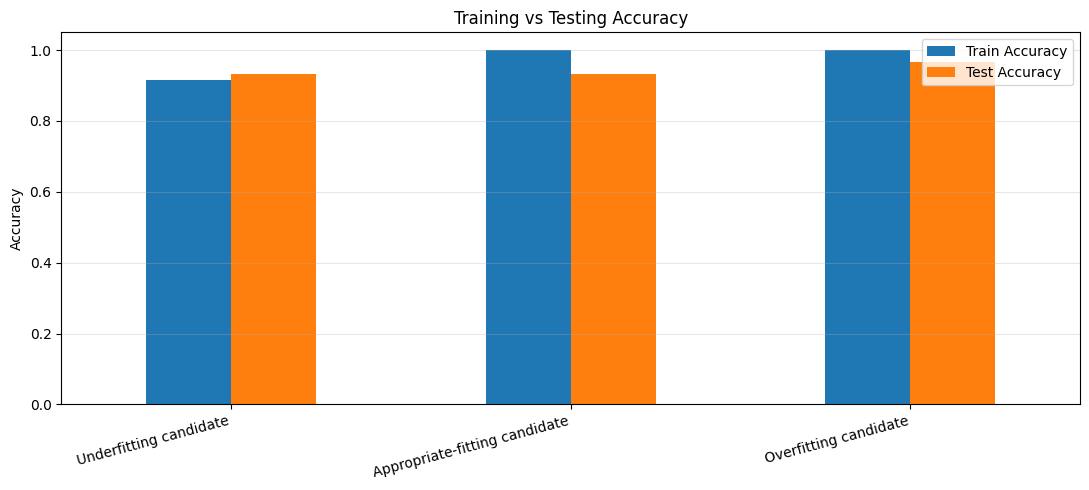

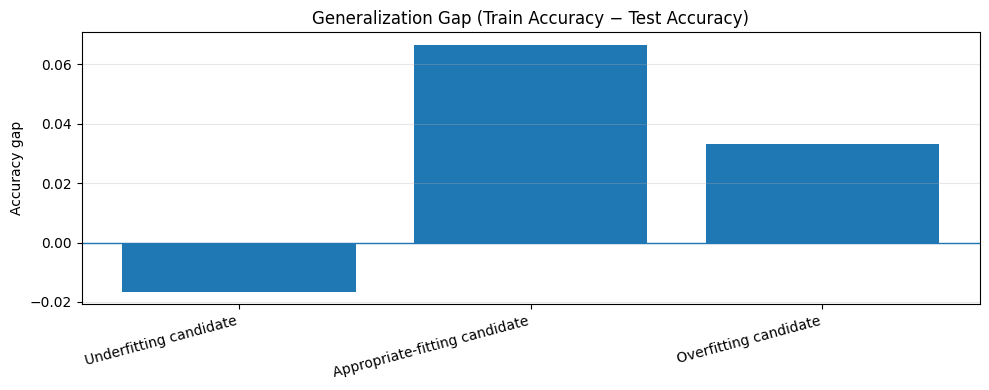

In [5]:
plot_df = results_df.set_index("Model")[["Train Accuracy", "Test Accuracy"]]
ax = plot_df.plot(kind="bar", figsize=(11, 5), ylim=(0, 1.05))
ax.set_title("Training vs Testing Accuracy")
ax.set_ylabel("Accuracy")
ax.set_xlabel("")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
plt.bar(results_df["Model"], results_df["Generalization Gap"])
plt.axhline(0, linewidth=1)
plt.title("Generalization Gap (Train Accuracy − Test Accuracy)")
plt.ylabel("Accuracy gap")
plt.xticks(rotation=15, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Training Loss Curves

`MLPClassifier` records training loss after each iteration. Interpret loss alongside test accuracy: a low training loss alone does not guarantee generalization.

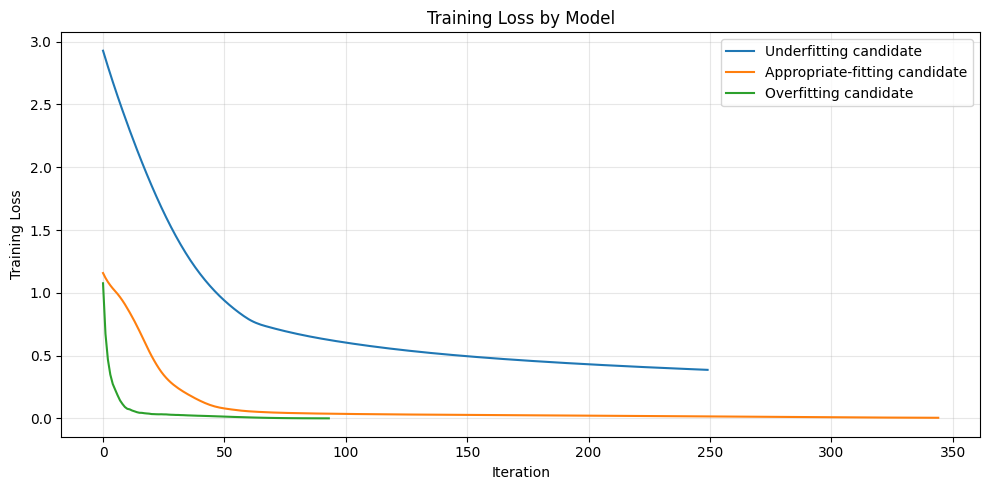

In [6]:
plt.figure(figsize=(10, 5))
for name, model in models.items():
    if hasattr(model, "loss_curve_"):
        plt.plot(model.loss_curve_, label=name)
plt.xlabel("Iteration")
plt.ylabel("Training Loss")
plt.title("Training Loss by Model")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Confusion Matrices

Confusion matrices show the number of correct predictions and which Iris classes are confused with one another.

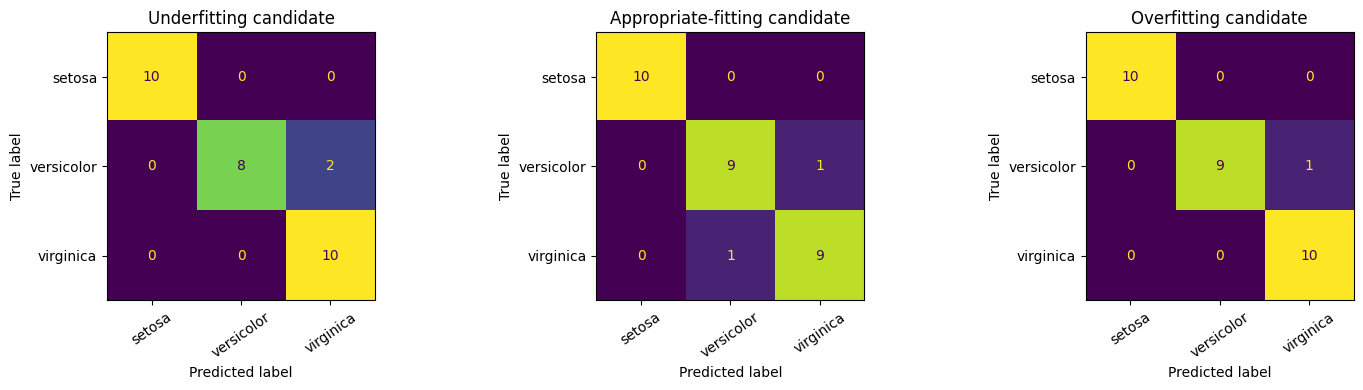

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, test_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, test_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=iris.target_names)
    disp.plot(ax=ax, colorbar=False, values_format="d")
    ax.set_title(name)
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

## 8. Classification Reports

Precision, recall, and F1-score provide more detail about each model's class-wise performance.

In [8]:
for name, test_pred in predictions.items():
    print("=" * 65)
    print(name)
    print("=" * 65)
    print(classification_report(y_test, test_pred, target_names=iris.target_names, zero_division=0))

Underfitting candidate
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.80      0.89        10
   virginica       0.83      1.00      0.91        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30

Appropriate-fitting candidate
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

Overfitting candidate
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10


## 9. Automatic Fit Diagnosis

This rule-based label is an educational heuristic, not a universal statistical rule. Check the plots and actual metrics before reaching a conclusion.

In [9]:
def fitting_diagnosis(row):
    train_acc = row["Train Accuracy"]
    test_acc = row["Test Accuracy"]
    gap = row["Generalization Gap"]
    if train_acc < 0.85 and test_acc < 0.85:
        return "Possible underfitting"
    if train_acc >= 0.95 and gap >= 0.08:
        return "Possible overfitting"
    if train_acc >= 0.85 and test_acc >= 0.85 and abs(gap) < 0.08:
        return "Reasonable fit / good generalization"
    if gap >= 0.08:
        return "Generalization gap — inspect for overfitting"
    return "Mixed result — inspect metrics and confusion matrix"

results_df["Diagnosis"] = results_df.apply(fitting_diagnosis, axis=1)
display(results_df.style.format({
    "Train Accuracy": "{:.3f}", "Test Accuracy": "{:.3f}", "Generalization Gap": "{:.3f}"
}))

,Model,Architecture,Train Accuracy,Test Accuracy,Generalization Gap,Iterations,Diagnosis
0,Underfitting candidate,"(2,)",0.917,0.933,-0.017,250,Reasonable fit / good generalization
1,Appropriate-fitting candidate,"(16, 8)",1.000,0.933,0.067,345,Reasonable fit / good generalization
2,Overfitting candidate,"(128, 128)",1.000,0.967,0.033,94,Reasonable fit / good generalization


## 10. Methods to Improve the Models

### If the model underfits
- Increase the number of neurons or hidden layers.
- Train for more iterations if it has not converged.
- Reduce excessive regularization.
- Check whether the input features contain enough information.

### If the model overfits
- Reduce network size.
- Increase regularization (`alpha`).
- Collect more data or use data augmentation where appropriate.
- Use early stopping based on validation performance.
- Select the simplest model that performs well on unseen data.

### If the model fits well
- Keep the model relatively simple.
- Verify performance with a validation set or cross-validation.
- Avoid adding complexity without measurable improvement.

## 11. Written Analysis

Use the actual values from the results table in your final observation.

1. **Underfitting:** identify a model with relatively low training and test accuracy. Its capacity or training may be insufficient to capture the patterns in the data.
2. **Appropriate fitting:** identify a model with good training and test accuracy and a small generalization gap.
3. **Overfitting:** identify a model with very high training accuracy but lower test accuracy and a larger gap. It may have learned details that do not generalize.
4. **Improvement:** increase model capacity or reduce regularization for underfitting; reduce complexity, increase regularization, use early stopping, or collect more data for overfitting.

**Important:** Iris is a small but relatively easy dataset, so the large network may still generalize well on a particular split. Report what the metrics actually show rather than claiming overfitting if the test gap is small.

## 12. Conclusion

This project compares three neural networks of different complexity on the same Iris training and testing split. Training accuracy measures how well a model fits the examples it learned from, while testing accuracy indicates how well it generalizes.

A model that is too simple may underfit; a model that is unnecessarily complex may overfit; and a model with balanced complexity can achieve good performance on both. The best model should be selected from the measured results, not architecture size alone.